Reimplement of https://oemof-solph.readthedocs.io/en/v0.6.4/examples/emission_constraint.html

## 1. Build

In [4]:
# Setup of the ES

import matplotlib.pyplot as plt
import pandas as pd

from oemof import solph
from oemof.solph import constraints

energysystem = solph.EnergySystem(
    timeindex=solph.create_time_index(year=2026,interval=1,number=3)
)

# Bus
## Gas
bus_gas = solph.Bus(label="Gas")
## Electro
bus_ele = solph.Bus(label="Electricity")

energysystem.add(bus_gas, bus_ele)

# Sources
## green electricity
commodity_biogas = solph.components.Source(
    label="Commodity biogas",
    outputs={bus_ele: solph.Flow(
        nominal_capacity=100,
        variable_costs=10,
        fix=[0.1,0.2,0.3],
        custom_properties={"emission_factor": 0.01},
    )}
)

## natural gas
commodity_natgas = solph.components.Source(
    label="Commodity natgas",
    outputs={bus_gas: solph.Flow(
        variable_costs=10,
        custom_properties={"emission_factor": 0.2},
    )}
)

energysystem.add(commodity_biogas, commodity_natgas)

# DEMAND
demand_ele = solph.components.Sink(
    label="Electricity demand",
    inputs={bus_ele: solph.Flow(
        nominal_capacity=200,
        variable_costs=10,
        fix=[0.1,0.2,0.4],
    )},
)

energysystem.add(demand_ele)

# CONVERT gas -> ele
power_plant = solph.components.Converter(
    label="power plant",
    inputs={bus_gas: solph.Flow()},
    outputs={bus_ele: solph.Flow(nominal_capacity=200)},
    conversion_factors={bus_ele: 0.58},
)
energysystem.add(power_plant)



## 2. Visualize

In [ ]:
from helpers.visualize import plot_energy_system
plot_energy_system(energysystem)

## 3. Model + Add emission constraint

In [6]:
# init
model = solph.Model(energysystem)

# add emission constraint
constraints.emission_limit(model, limit=100)

# print out the emission constraint
model.integral_limit_emission_factor_upper_limit.pprint()
model.integral_limit_emission_factor.pprint()

integral_limit_emission_factor_upper_limit : Size=1, Index=None, Active=True
    Key  : Lower : Body                           : Upper : Active
    None :  -Inf : integral_limit_emission_factor : 100.0 :   True
integral_limit_emission_factor : Size=1, Index=None
    Key  : Expression
    None : 0.01*flow[Commodity biogas,Electricity,0] + 0.01*flow[Commodity biogas,Electricity,1] + 0.01*flow[Commodity biogas,Electricity,2] + 0.2*flow[Commodity natgas,Gas,0] + 0.2*flow[Commodity natgas,Gas,1] + 0.2*flow[Commodity natgas,Gas,2]


0.01*flow[Commodity biogas,Electricity,0] + 0.01*flow[Commodity biogas,Electricity,1] + 0.01*flow[Commodity biogas,Electricity,2] + 0.2*flow[Commodity natgas,Gas,0] + 0.2*flow[Commodity natgas,Gas,1] + 0.2*flow[Commodity natgas,Gas,2]

==

biogas: fix=[0.1,0.2,0.3],nominal_capacity=100, --> 10,20,30
demand: fix=[0.1,0.2,0.4],nominal_capacity=200, --> 20,40,80
rest: 10, 20, 50

0.01*10 = 0.1
+ 0.01*20 = 0.2
+ 0.01*30 = 0.3
+ 0.2*10 / 0.58 = 3.5
+ 0.2*20 / 0.58 = 7.0
+ 0.2*50 / 0.58 = 17.2

==

28.3



## 4. Solve

In [9]:
results = model.solve()

print("Solved!")

Solved!


## 5. Plot Results

28.186207


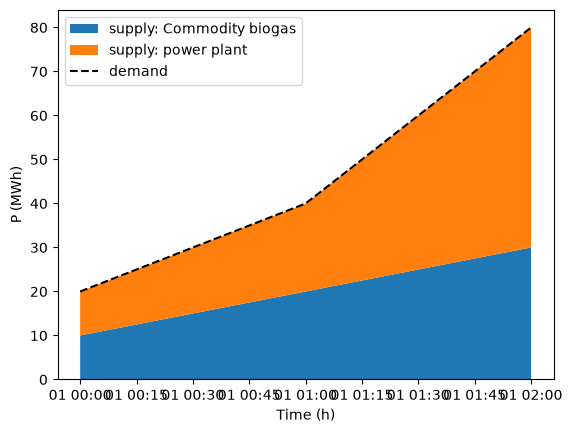

In [12]:
# print out the amount of emissions from the emission constraint
print(model.integral_limit_emission_factor())


data = results["flow"]
outflows = data.xs("Electricity", axis=1, level=0, drop_level=False)
inflows = data.xs("Electricity", axis=1, level=1, drop_level=False)

fig = plt.figure()
ax = fig.add_subplot()

ax.stackplot(
    inflows.index,
    inflows.T,
    labels=[f"supply: {col[0]}" for col in inflows.columns],
)
ax.plot(outflows, "k--", label="demand")

ax.legend()

ax.set_xlabel("Time (h)")
ax.set_ylabel("P (MWh)")
plt.show()